IS_SOLD CLASSIFICATION - V2 (FEATURE ENGINEERING)

 Data Loaded: (250, 8)

 Creating 7 new features...
7 new features created

Features: 20
Samples: 250

Train: (200, 20), Test: (50, 20)

MODEL: Random Forest
Accuracy: 0.5600
              precision    recall  f1-score   support

    Not Sold       0.63      0.63      0.63        30
        Sold       0.45      0.45      0.45        20

    accuracy                           0.56        50
   macro avg       0.54      0.54      0.54        50
weighted avg       0.56      0.56      0.56        50


MODEL: Gradient Boosting
Accuracy: 0.6200
              precision    recall  f1-score   support

    Not Sold       0.64      0.83      0.72        30
        Sold       0.55      0.30      0.39        20

    accuracy                           0.62        50
   macro avg       0.59      0.57      0.56        50
weighted avg       0.60      0.62      0.59        50


MODEL: XGBoost
Accuracy: 0.5200
              precision    recall  f1-score 

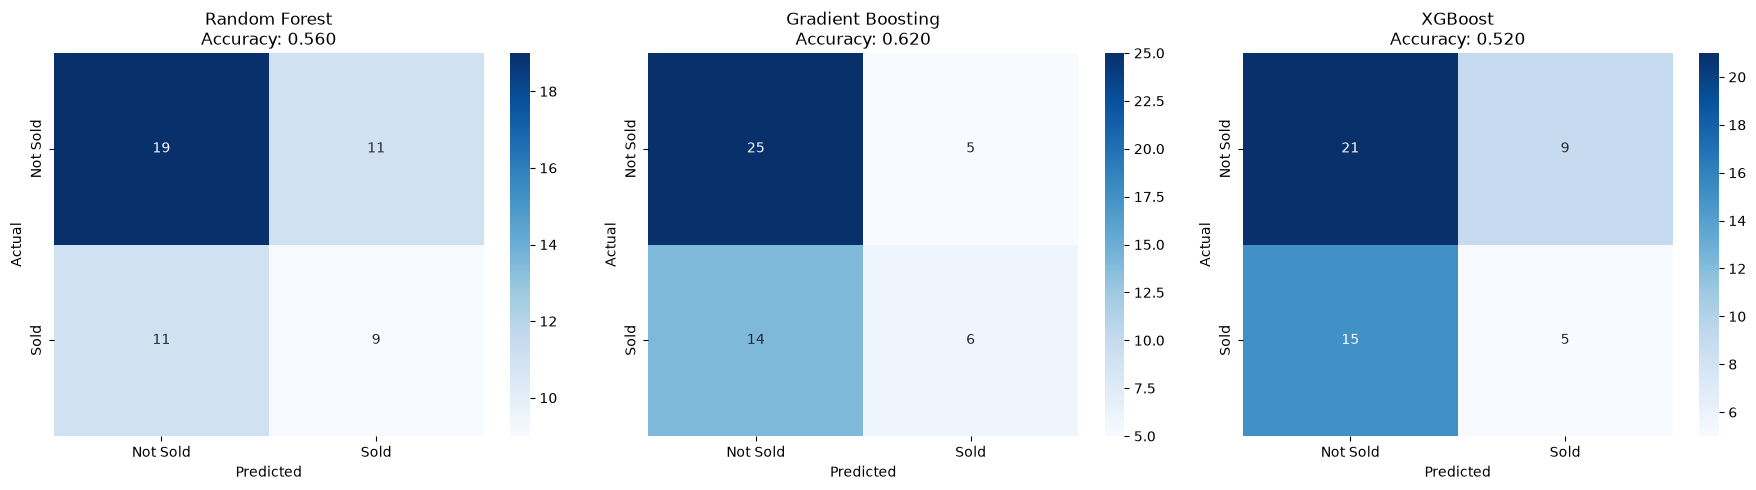

 is_sold_confusion_matrix_v2.png saved

V2 - DONE WITH IS_SOLD CLASSIFICATION


In [1]:
# File: 05_feature_engineering.ipynb
# Version: V2 - Feature Engineering
# Author: Youssef
# ------------------------------------------------

import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import warnings
warnings.filterwarnings('ignore')

print("=" * 60)
print("IS_SOLD CLASSIFICATION - V2 (FEATURE ENGINEERING)")
print("=" * 60)

# ==========================================
# 1. Load Data

df = pd.read_csv('../../1_Data/cleaned_data.csv')    # ← عدّلنا الـ Path
df = df.drop('Property_ID', axis=1)
df['Is_Sold'] = df['Is_Sold'].map({'Yes': 1, 'No': 0})

print(f"\n Data Loaded: {df.shape}")

# ==========================================
# 2. FEATURE ENGINEERING ⭐

print("\n Creating 7 new features...")

df['Total_Rooms'] = df['Bedrooms'] + df['Bathrooms']
df['Area_per_Bedroom'] = df['Area_SqM'] / df['Bedrooms']
df['Bathroom_Ratio'] = df['Bathrooms'] / df['Bedrooms']
df['Is_Luxury'] = ((df['Area_SqM'] > 300) & (df['Bedrooms'] >= 4)).astype(int)
df['Price_per_SqM'] = df['Price_EGP'] / df['Area_SqM']
df['Is_Expensive'] = (df['Price_per_SqM'] > df['Price_per_SqM'].median()).astype(int)
df['Days_Category'] = pd.cut(df['Days_On_Market'], bins=[0, 30, 90, 180], 
                              labels=['Fast', 'Medium', 'Slow'])

print(f"7 new features created")

# ------------------------------------------------
# 3. Encoding

categorical_cols = ['Location', 'Property_Type', 'Days_Category']
df_encoded = pd.get_dummies(df, columns=categorical_cols, drop_first=True)

# ------------------------------------------------
# 4. Features & Target

X = df_encoded.drop('Is_Sold', axis=1)
y = df_encoded['Is_Sold']

print(f"\nFeatures: {X.shape[1]}")
print(f"Samples: {X.shape[0]}")

# ------------------------------------------------
# 5. Split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(f"\nTrain: {X_train.shape}, Test: {X_test.shape}")

# ------------------------------------------------
# 6. Models

models = {
    'Random Forest': RandomForestClassifier(
        n_estimators=300, max_depth=15, min_samples_split=5,
        min_samples_leaf=2, random_state=42, class_weight='balanced'
    ),
    'Gradient Boosting': GradientBoostingClassifier(
        n_estimators=200, learning_rate=0.05, max_depth=5, random_state=42
    ),
    'XGBoost': XGBClassifier(
        n_estimators=300, learning_rate=0.05, max_depth=5,
        random_state=42, eval_metric='logloss',
        scale_pos_weight=(y_train == 0).sum() / (y_train == 1).sum()
    )
}

results = []
predictions = {}

for name, model in models.items():
    print(f"\n{'='*60}")
    print(f"MODEL: {name}")
    print(f"{'='*60}")
    
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    acc = accuracy_score(y_test, pred)
    
    print(f"Accuracy: {acc:.4f}")
    print(classification_report(y_test, pred, target_names=['Not Sold', 'Sold']))
    
    results.append({'Model': name, 'Test Accuracy': acc})
    predictions[name] = pred

# ------------------------------------------------
# 7. Cross-Validation (5-Fold)

print("\n" + "=" * 60)
print("CROSS-VALIDATION (5-Fold)")
print("=" * 60)

for name, model in models.items():
    scores = cross_val_score(model, X, y, cv=5, scoring='accuracy')
    print(f"{name}: {scores.mean():.4f} (+/- {scores.std():.4f})")
    
    for r in results:
        if r['Model'] == name:
            r['CV Mean'] = scores.mean()

# ------------------------------------------------
# 8. Comparison

print("\n" + "=" * 60)
print("FINAL COMPARISON")
print("=" * 60)

results_df = pd.DataFrame(results).sort_values('Test Accuracy', ascending=False).reset_index(drop=True)
print(results_df)

best_name = results_df.iloc[0]['Model']
best_acc = results_df.iloc[0]['Test Accuracy']
print(f"\n Best Model: {best_name} with {best_acc:.4f}")

# ------------------------------------------------
# 9. Save Best

if best_name == 'Random Forest':
    joblib.dump(models['Random Forest'], 'is_sold_classifier_v2.pkl')
elif best_name == 'Gradient Boosting':
    joblib.dump(models['Gradient Boosting'], 'is_sold_classifier_v2.pkl')
else:
    joblib.dump(models['XGBoost'], 'is_sold_classifier_v2.pkl')

print(f"is_sold_classifier_v2.pkl saved")

# ------------------------------------------------
# 10. Confusion Matrices

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, pred)
    acc = accuracy_score(y_test, pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['Not Sold', 'Sold'], yticklabels=['Not Sold', 'Sold'])
    ax.set_title(f'{name}\nAccuracy: {acc:.3f}')
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')

plt.tight_layout()
plt.savefig('is_sold_confusion_matrix_v2.png', dpi=150, bbox_inches='tight')
plt.show()
print(" is_sold_confusion_matrix_v2.png saved")

print("\n" + "=" * 60)
print("V2 - DONE WITH IS_SOLD CLASSIFICATION")
print("=" * 60)